---
# Practice 1: Phân tích đồ thị với NetworkX

In [1]:
import random, zipfile
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.metrics.pairwise import cosine_similarity

## 1.1. Đọc đồ thị từ file ma trận kề
Đầu tiên ta tạo file `graph.txt` mẫu (ma trận kề có trọng số, 0 = không có cạnh). Đồ thị gồm 2 thành phần liên thông: {A..F} và {G, H}.
Nếu bạn đã có file riêng, chỉ cần đổi đường dẫn `FILE`.

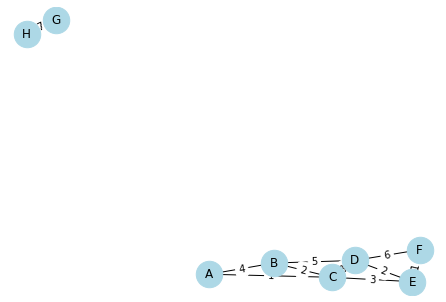

In [2]:
labels = list("ABCDEFGH")
A = np.array([
    [0, 4, 1, 0, 0, 0, 0, 0],
    [4, 0, 2, 5, 0, 0, 0, 0],
    [1, 2, 0, 8, 3, 0, 0, 0],
    [0, 5, 8, 0, 2, 6, 0, 0],
    [0, 0, 3, 2, 0, 1, 0, 0],
    [0, 0, 0, 6, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 7],
    [0, 0, 0, 0, 0, 0, 7, 0]])
FILE = "graph.txt"
np.savetxt(FILE, A, fmt="%d")          # ghi file ma trận kề

# Đọc file -> đồ thị NetworkX
M = np.loadtxt(FILE, dtype=int)
G = nx.from_numpy_array(M)                                   # đồ thị vô hướng có trọng số
G = nx.relabel_nodes(G, {i: l for i, l in enumerate(labels)})  # đổi tên đỉnh 0..7 -> A..H

pos = nx.spring_layout(G, seed=1)
nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=700)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))
plt.show()

## 1.2. Bậc của các đỉnh

In [3]:
print("Bậc từng đỉnh:", dict(G.degree()))

Bậc từng đỉnh: {'A': 2, 'B': 3, 'C': 4, 'D': 4, 'E': 3, 'F': 2, 'G': 1, 'H': 1}


## 1.3. Duyệt đồ thị DFS / BFS

In [4]:
start = "A"
print("DFS:", list(nx.dfs_preorder_nodes(G, source=start)))
print("BFS:", [start] + [v for u, v in nx.bfs_edges(G, source=start)])

DFS: ['A', 'B', 'C', 'D', 'E', 'F']
BFS: ['A', 'B', 'C', 'D', 'E', 'F']


## 1.4. Số thành phần liên thông

In [5]:
print("Số thành phần liên thông:", nx.number_connected_components(G))
for i, comp in enumerate(nx.connected_components(G), 1):
    print(f"  Thành phần {i}:", sorted(comp))

Số thành phần liên thông: 2
  Thành phần 1: ['A', 'B', 'C', 'D', 'E', 'F']
  Thành phần 2: ['G', 'H']


## 1.5. Đường đi ngắn nhất giữa 2 điểm (Dijkstra)

In [6]:
src, dst = "A", "F"
path = nx.dijkstra_path(G, src, dst, weight="weight")
length = nx.dijkstra_path_length(G, src, dst, weight="weight")
print(f"Đường đi ngắn nhất {src} -> {dst}: {path}, độ dài = {length}")

Đường đi ngắn nhất A -> F: ['A', 'C', 'E', 'F'], độ dài = 5


## 1.6. Cây khung nhỏ nhất (Kruskal)

Các cạnh của cây khung: [('A', 'C', 1), ('B', 'C', 2), ('C', 'E', 3), ('D', 'E', 2), ('E', 'F', 1), ('G', 'H', 7)]
Tổng trọng số: 16.0


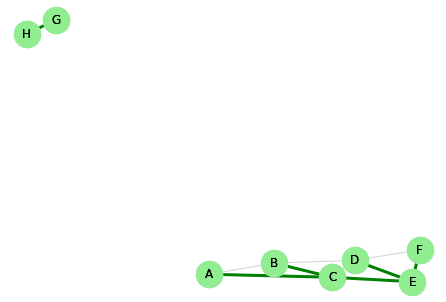

In [7]:
T = nx.minimum_spanning_tree(G, algorithm="kruskal", weight="weight")  # với đồ thị không liên thông -> rừng khung
print("Các cạnh của cây khung:", list(T.edges(data="weight")))
print("Tổng trọng số:", T.size(weight="weight"))

nx.draw(G, pos, with_labels=True, node_color="lightgray", edge_color="lightgray", node_size=700)
nx.draw(T, pos, with_labels=True, node_color="lightgreen", edge_color="green", width=3, node_size=700)
plt.show()

---
# Practice 2: Node2Vec + phân cụm trên dữ liệu Capital Bikeshare 2017



## Bước 1. Đọc dữ liệu từ file zip


In [8]:
ZIP_FILE = "2017-capitalbikeshare-tripdata.zip"     # đổi tên/đường dẫn nếu cần
keep = {"duration", "start station", "end station", "start_station_name", "end_station_name"}

z = zipfile.ZipFile(ZIP_FILE)
csv_names = [n for n in z.namelist() if n.endswith(".csv") and "__MACOSX" not in n]
print("Các file CSV trong zip:", csv_names)       # muốn chạy nhanh hơn: csv_names = csv_names[:1]

df = pd.concat([pd.read_csv(z.open(n), usecols=lambda c: c.strip().lower() in keep) for n in csv_names],
               ignore_index=True)
df.columns = df.columns.str.strip().str.lower()
df = df.rename(columns={"start station": "start_station_name", "end station": "end_station_name"})
df = df.dropna(subset=["start_station_name", "end_station_name"])
print("Số chuyến đi:", len(df))
df.head()

Các file CSV trong zip: ['2017Q1-capitalbikeshare-tripdata.csv', '2017Q2-capitalbikeshare-tripdata.csv', '2017Q3-capitalbikeshare-tripdata.csv', '2017Q4-capitalbikeshare-tripdata.csv']
Số chuyến đi: 3757777


,duration,start_station_name,end_station_name
0,221,3rd & Tingey St SE,M St & New Jersey Ave SE
1,1676,Lincoln Memorial,8th & D St NW
2,1356,Henry Bacon Dr & Lincoln Memorial Circle NW,New York Ave & 15th St NW
3,1327,Henry Bacon Dr & Lincoln Memorial Circle NW,New York Ave & 15th St NW
4,1636,Lincoln Memorial,8th & D St NW


## Bước 2. Xây dựng đồ thị các trạm xe
Bỏ các cạnh có quá ít chuyến (`MIN_TRIPS`) để đồ thị gọn, rồi lấy thành phần liên thông lớn nhất.

In [9]:
MIN_TRIPS = 20
edges = df.groupby(["start_station_name", "end_station_name"]).size().reset_index(name="weight")
edges = edges[(edges.start_station_name != edges.end_station_name) & (edges.weight >= MIN_TRIPS)]

G2 = nx.from_pandas_edgelist(edges, "start_station_name", "end_station_name", "weight")
G2 = G2.subgraph(max(nx.connected_components(G2), key=len)).copy()
nodes = list(G2.nodes())
print("Số đỉnh (trạm):", G2.number_of_nodes(), "| Số cạnh:", G2.number_of_edges())

Số đỉnh (trạm): 443 | Số cạnh: 16370


## Bước 3. Node2Vec tự xây dựng (theo mã giả)


In [10]:
def node2vec_walk(G, start, length, p, q):
    """Tạo 1 random walk bắt đầu từ đỉnh start"""
    walk = [start]
    while len(walk) < length:
        curr = walk[-1]
        nbrs = list(G.neighbors(curr))
        if not nbrs:
            break
        prev = walk[-2] if len(walk) > 1 else None
        weights = []
        for x in nbrs:
            w = G[curr][x]["weight"]
            if prev is None:            weights.append(w)        # bước đầu tiên
            elif x == prev:             weights.append(w / p)    # quay lại
            elif G.has_edge(x, prev):   weights.append(w)        # đi quanh
            else:                       weights.append(w / q)    # đi xa
        walk.append(random.choices(nbrs, weights=weights)[0])
    return walk

def learn_features(G, d=64, r=10, l=20, k=5, p=1.0, q=0.5):
    """d: số chiều, r: số walk/đỉnh, l: độ dài walk, k: context size"""
    walks = [node2vec_walk(G, u, l, p, q) for _ in range(r) for u in G.nodes()]
    return Word2Vec(walks, vector_size=d, window=k, min_count=1, sg=1, workers=2, epochs=5, seed=42)

random.seed(42)
w2v = learn_features(G2)
emb = np.array([w2v.wv[n] for n in nodes])        # ma trận embedding (số trạm x 64)
print("Kích thước embedding:", emb.shape)

Kích thước embedding: (443, 64)


## 2.1. Phân cụm bằng Node2Vec
Áp dụng K-Means lên **vector embedding** (mang thông tin cấu trúc đồ thị). Chọn số cụm bằng hệ số silhouette.

In [11]:
for k in range(2, 9):
    lab = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(emb)
    print(f"k={k}: silhouette = {silhouette_score(emb, lab):.3f}")

k=2: silhouette = 0.269
k=3: silhouette = 0.283
k=4: silhouette = 0.317
k=5: silhouette = 0.345
k=6: silhouette = 0.305
k=7: silhouette = 0.339
k=8: silhouette = 0.369


In [12]:
K = 4   # chọn k dựa trên silhouette ở trên (có thể đổi)
labels_n2v = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(emb)
print("Kích thước các cụm (Node2Vec):", np.bincount(labels_n2v))

Kích thước các cụm (Node2Vec): [ 65 238  59  81]


## 2.2. Phân cụm bằng K-Means thông thường
Không dùng cấu trúc đồ thị, chỉ dùng **đặc trưng thô** của từng trạm: bậc, tổng số chuyến, số chuyến đi/đến và thời gian thuê trung bình.

In [13]:
feat = pd.DataFrame({
    "degree":    [G2.degree(n) for n in nodes],                    # số trạm kết nối
    "trips":     [G2.degree(n, weight="weight") for n in nodes],   # tổng số chuyến trong đồ thị
    "out_trips": df.groupby("start_station_name").size().reindex(nodes).values,
    "in_trips":  df.groupby("end_station_name").size().reindex(nodes).values}, index=nodes)
if "duration" in df.columns:
    feat["avg_duration"] = df.groupby("start_station_name")["duration"].mean().reindex(nodes).values
feat = feat.fillna(feat.mean())

X_raw = StandardScaler().fit_transform(feat)
labels_km = KMeans(n_clusters=K, n_init=10, random_state=0).fit_predict(X_raw)
print("Kích thước các cụm (K-Means):", np.bincount(labels_km))
feat.head()

Kích thước các cụm (K-Means): [221  24 135  63]


,degree,trips,out_trips,in_trips,avg_duration
10th & E St NW,172,16545,15410,17504,1536.862038
10th & Florida Ave NW,114,8256,8990,8367,748.103226
10th & G St NW,174,12805,11665,13353,1275.353450
10th & K St NW,179,18968,19381,19363,1024.689541
10th & U St NW,139,15276,16287,16079,755.438509


## 2.3. Trực quan hoá & nhận xét
Vì dữ liệu không có toạ độ, ta vẽ: (a) t-SNE của embedding Node2Vec và (b) đồ thị mạng lưới trạm, tô màu theo cụm.

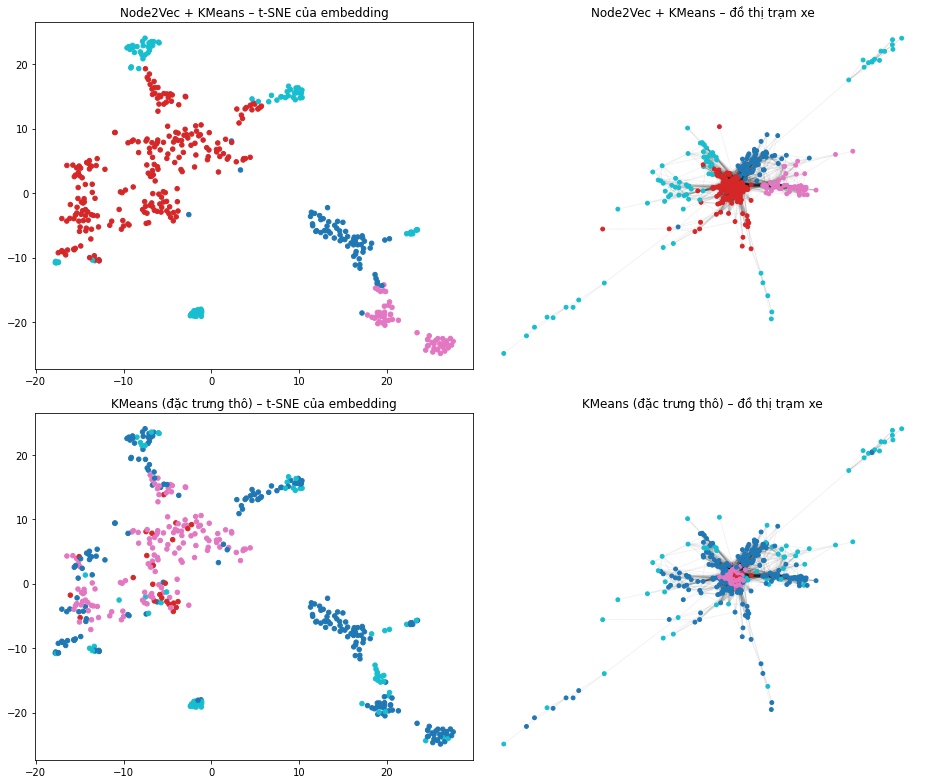

Silhouette Node2Vec (trên embedding): 0.317
Silhouette KMeans   (trên đặc trưng): 0.456
Độ tương đồng 2 cách phân cụm (ARI): 0.134


In [14]:
emb2d = TSNE(n_components=2, random_state=0, perplexity=min(30, len(nodes) - 1)).fit_transform(emb)
pos2 = nx.spring_layout(G2, seed=1, weight="weight", iterations=50)    # vị trí đỉnh để vẽ đồ thị

fig, ax = plt.subplots(2, 2, figsize=(13, 11))
for row, (lab, name) in enumerate([(labels_n2v, "Node2Vec + KMeans"), (labels_km, "KMeans (đặc trưng thô)")]):
    ax[row, 0].scatter(emb2d[:, 0], emb2d[:, 1], c=lab, cmap="tab10", s=20)
    ax[row, 0].set_title(f"{name} – t-SNE của embedding")
    nx.draw_networkx_edges(G2, pos2, ax=ax[row, 1], alpha=0.05)
    nx.draw_networkx_nodes(G2, pos2, ax=ax[row, 1], node_size=15, node_color=lab, cmap="tab10")
    ax[row, 1].set_title(f"{name} – đồ thị trạm xe"); ax[row, 1].axis("off")
plt.tight_layout(); plt.show()

print("Silhouette Node2Vec (trên embedding):", round(silhouette_score(emb, labels_n2v), 3))
print("Silhouette KMeans   (trên đặc trưng):", round(silhouette_score(X_raw, labels_km), 3))
print("Độ tương đồng 2 cách phân cụm (ARI):", round(adjusted_rand_score(labels_n2v, labels_km), 3))

In [15]:
# Xem mỗi cụm Node2Vec gồm những trạm nào (5 trạm nhộn nhịp nhất mỗi cụm) và đặc trưng trung bình
feat["cum_node2vec"] = labels_n2v
for c in range(K):
    top = feat[feat.cum_node2vec == c].sort_values("trips", ascending=False).head(5).index.tolist()
    print(f"Cụm {c} ({(labels_n2v == c).sum()} trạm):", top)
feat.groupby("cum_node2vec").mean().round(1)

Cụm 0 (65 trạm): ['Lynn & 19th St North', '37th & O St NW / Georgetown University', 'Iwo Jima Memorial/N Meade & 14th St N', 'Court House Metro / 15th & N Uhle St ', 'Ballston Metro / N Stuart & 9th St N']
Cụm 1 (238 trạm): ['Columbus Circle / Union Station', 'Lincoln Memorial', 'Jefferson Dr & 14th St SW', 'Massachusetts Ave & Dupont Circle NW', '15th & P St NW']
Cụm 2 (59 trạm): ['Braddock Rd Metro', 'Crystal City Metro / 18th & Bell St', '20th & Crystal Dr', 'Pentagon City Metro / 12th & S Hayes St', '12th & Army Navy Dr']
Cụm 3 (81 trạm): ['Takoma Metro', 'Connecticut & Nebraska Ave NW', 'River Rd & Landy Ln', 'Friendship Hts Metro/Wisconsin Ave & Wisconsin Cir', 'Carroll & Ethan Allen Ave']


,degree,trips,out_trips,in_trips,avg_duration
cum_node2vec,,,,,
0,37.0,2987.4,3415.0,3123.3,1145.6
1,117.3,13004.2,13682.1,13795.9,1124.6
2,25.4,2457.3,2879.5,2963.2,1241.5
3,11.5,1013.4,1200.8,1041.5,1541.6


---
# Practice 3: Content-based Recommendation (dự đoán điểm môn còn thiếu)
## 3.1. Tự xây dựng bộ dữ liệu điểm


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

rng = np.random.default_rng(1)

# Môn học + mô tả nội dung
subjects = {
    "Python":        "lập trình python code thuật toán",
    "Java":          "lập trình java code hướng đối tượng",
    "CauTrucDuLieu": "lập trình thuật toán cấu trúc dữ liệu",
    "GiaiTich":      "toán giải tích hàm số đạo hàm",
    "DaiSo":         "toán đại số ma trận vector",
    "XacSuat":       "toán xác suất thống kê",
    "BigData":       "dữ liệu lớn hadoop spark thuật toán",
    "KhaiThacDL":    "dữ liệu khai thác thống kê thuật toán",
    "MayHoc":        "dữ liệu mô hình ma trận thống kê python",
    "KhaiThacDoThi": "dữ liệu đồ thị thuật toán python"}
subj_names = list(subjects.keys())
group = {"Python": 0, "Java": 0, "CauTrucDuLieu": 0,            # nhóm lập trình
         "GiaiTich": 1, "DaiSo": 1, "XacSuat": 1,               # nhóm toán
         "BigData": 2, "KhaiThacDL": 2, "MayHoc": 2, "KhaiThacDoThi": 2}   # nhóm dữ liệu

n_students, n_subjects = 20, len(subj_names)
students = [f"SV{i+1:02d}" for i in range(n_students)]

# Điểm đầy đủ = năng lực chung + thế mạnh theo nhóm + nhiễu
ability  = rng.normal(7, 1, n_students)
strength = rng.normal(0, 1.2, (n_students, 3))
full = np.array([[ability[u] + strength[u, group[s]] + rng.normal(0, 0.4) for s in subj_names]
                 for u in range(n_students)])
full = np.clip(np.round(full, 1), 0, 10)

# Ẩn 40% điểm -> ma trận điểm với NaN (chưa học)
Y = full.copy()
Y[rng.random(Y.shape) < 0.4] = np.nan

data = pd.DataFrame(Y, index=students, columns=subj_names)
print("Tỉ lệ điểm bị thiếu:", round(np.isnan(Y).mean(), 2))
data.head()

Tỉ lệ điểm bị thiếu: 0.42


,Python,Java,CauTrucDuLieu,GiaiTich,DaiSo,XacSuat,BigData,KhaiThacDL,MayHoc,KhaiThacDoThi
SV01,7.7,7.4,6.7,6.5,7.4,NaN,NaN,NaN,9.1,9.1
SV02,9.4,NaN,9.0,NaN,NaN,NaN,5.5,5.6,5.0,5.7
SV03,6.9,7.5,7.1,7.1,NaN,NaN,7.2,7.0,NaN,NaN
SV04,5.7,6.0,5.9,NaN,NaN,NaN,NaN,4.6,NaN,NaN
SV05,NaN,6.8,NaN,NaN,NaN,NaN,8.2,8.9,NaN,NaN


In [17]:
ratings = data.stack().dropna().reset_index()
ratings.columns = ["student", "subject", "score"]
ratings["u"] = ratings.student.map({s: i for i, s in enumerate(students)})
ratings["i"] = ratings.subject.map({s: i for i, s in enumerate(subj_names)})

test = ratings.sample(frac=0.2, random_state=0)
train = ratings.drop(test.index)
print("Số điểm train:", len(train), "| test:", len(test))

# Ma trận điểm chỉ chứa dữ liệu train (NaN = chưa biết hoặc đang bị ẩn)
Y_train = np.full((n_students, n_subjects), np.nan)
Y_train[train.u, train.i] = train.score

def rmse(df, pred_func):
    """RMSE trên tập test; pred_func(u, i) trả về điểm dự đoán"""
    err = [row.score - pred_func(row.u, row.i) for row in df.itertuples()]
    return np.sqrt(np.mean(np.square(err)))

Số điểm train: 93 | test: 23


## 3.2 – 3.3. Feature vector cho mỗi môn học (TF-IDF)
Mỗi **hàng** của `X` là feature vector của một môn học, được tính từ mô tả nội dung môn.

In [29]:
tfidf = TfidfVectorizer()
X = tfidf.fit_transform(subjects.values()).toarray()      # (số môn x số từ)
print("Kích thước ma trận TF-IDF:", X.shape)

# Tương thích cả scikit-learn cũ và mới
try:
    terms = tfidf.get_feature_names_out()
except AttributeError:
    terms = tfidf.get_feature_names()

pd.DataFrame(X, index=subj_names, columns=terms).round(2).head(4)

Kích thước ma trận TF-IDF: (10, 36)


,code,cấu,dữ,giải,hadoop,hàm,hình,hướng,java,khai,...,trúc,trận,tích,tượng,vector,xác,đại,đạo,đối,đồ
Python,0.50,0.00,0.00,0.00,0.0,0.00,0.0,0.00,0.00,0.0,...,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.00,0.00,0.0
Java,0.35,0.00,0.00,0.00,0.0,0.00,0.0,0.41,0.41,0.0,...,0.00,0.0,0.00,0.41,0.0,0.0,0.0,0.00,0.41,0.0
CauTrucDuLieu,0.00,0.48,0.28,0.00,0.0,0.00,0.0,0.00,0.00,0.0,...,0.48,0.0,0.00,0.00,0.0,0.0,0.0,0.00,0.00,0.0
GiaiTich,0.00,0.00,0.00,0.36,0.0,0.71,0.0,0.00,0.00,0.0,...,0.00,0.0,0.36,0.00,0.0,0.0,0.0,0.36,0.00,0.0


## 3.4. Ridge Regression cho từng sinh viên
Với mỗi sinh viên $u$: lấy các môn đã có điểm (train) → hồi quy `điểm ≈ X·w + b` để tìm $w_u$, $b_u$.

In [19]:
n_features = X.shape[1]
W = np.zeros((n_features, n_students))
b = np.zeros(n_students)

for u in range(n_students):
    rated = np.where(~np.isnan(Y_train[u]))[0]            # các môn sinh viên u đã học
    model = Ridge(alpha=1.0).fit(X[rated], Y_train[u, rated])
    W[:, u], b[u] = model.coef_, model.intercept_
print("W:", W.shape, "| b:", b.shape)

W: (36, 20) | b: (20,)


## 3.5. Dự đoán điểm: $\hat{Y} = X \cdot W + b$

In [20]:
Y_pred_cb = X.dot(W) + b            # (số môn x số sinh viên)
Y_pred_cb = np.clip(Y_pred_cb, 0, 10).T   # đổi về (sinh viên x môn) và giới hạn 0-10

# Ví dụ: dự đoán các môn còn thiếu của SV01
pd.DataFrame({"Điểm dự đoán": Y_pred_cb[0], "Điểm thật (nếu có)": full[0]}, index=subj_names).round(2)

,Điểm dự đoán,Điểm thật (nếu có)
Python,7.84,7.7
Java,7.58,7.4
CauTrucDuLieu,7.95,6.7
GiaiTich,7.14,6.5
DaiSo,7.65,7.4
XacSuat,7.95,7.3
BigData,8.03,8.6
KhaiThacDL,8.16,8.9
MayHoc,8.49,9.1
KhaiThacDoThi,8.50,9.1


## 3.6. Đánh giá bằng RMSE

In [21]:
rmse_cb = rmse(test, lambda u, i: Y_pred_cb[u, i])
print(f"RMSE Content-based (Ridge): {rmse_cb:.3f}")

RMSE Content-based (Ridge): 1.179


---
# Practice 4: User-User Collaborative Filtering


In [22]:
from sklearn.metrics.pairwise import cosine_similarity

user_mean = np.nanmean(Y_train, axis=1)                 # điểm TB của mỗi sinh viên
Y_norm = Y_train - user_mean[:, None]                   # chuẩn hoá
Y_norm = np.nan_to_num(Y_norm)                          # NaN -> 0 (chưa học = không có thông tin)
S = cosine_similarity(Y_norm)                           # ma trận tương đồng sinh viên x sinh viên

def predict_user_cf(u, i, k=5):
    others = np.where(~np.isnan(Y_train[:, i]))[0]      # SV đã có điểm môn i
    others = others[others != u]
    if len(others) == 0:
        return user_mean[u]
    top = others[np.argsort(-S[u, others])[:k]]         # k SV giống u nhất
    sims = S[u, top]
    return np.clip(user_mean[u] + sims.dot(Y_norm[top, i]) / (np.abs(sims).sum() + 1e-8), 0, 10)

for k in [3, 5, 10]:
    print(f"k = {k:2d} -> RMSE User-User CF: {rmse(test, lambda u, i: predict_user_cf(u, i, k)):.3f}")

k =  3 -> RMSE User-User CF: 1.106
k =  5 -> RMSE User-User CF: 1.115
k = 10 -> RMSE User-User CF: 1.126


---
# Practice 5: Matrix Factorization

## 5.1. Chuẩn bị dữ liệu


In [23]:
Y5 = Y_train.T                                  # (môn x sinh viên)
mask = ~np.isnan(Y5)                            # True = điểm đã biết
mu = np.nanmean(Y5, axis=0)                     # điểm TB mỗi sinh viên
Yn = np.where(mask, Y5 - mu, 0)                 # chuẩn hoá, NaN -> 0 (sẽ bị mask loại khi tính loss)

K, lamda = 3, 0.1
X5 = rng.normal(0, 0.1, (n_subjects, K))
W5 = rng.normal(0, 0.1, (K, n_students))

## 5.2. Hàm mất mát

In [24]:
def loss(X, W):
    E = mask * (X.dot(W) - Yn)                  # sai số chỉ tính trên điểm đã biết
    return 0.5 * np.sum(E ** 2) + 0.5 * lamda * (np.sum(X ** 2) + np.sum(W ** 2))

print("Loss ban đầu:", round(loss(X5, W5), 3))

Loss ban đầu: 27.134


## 5.3. Môn học được 1 sinh viên chấm, và sinh viên đã học 1 môn


In [25]:
def items_rated_by_user(u):
    """Các môn mà sinh viên u đã có điểm + điểm tương ứng"""
    ids = np.where(mask[:, u])[0]
    return ids, Y5[ids, u]

def users_who_rated_item(i):
    """Các sinh viên đã có điểm môn i + điểm tương ứng"""
    ids = np.where(mask[i, :])[0]
    return ids, Y5[i, ids]

print("SV01 đã học môn:", [subj_names[i] for i in items_rated_by_user(0)[0]])
print("Môn Python có điểm của SV:", [students[u] for u in users_who_rated_item(0)[0]])

SV01 đã học môn: ['Python', 'Java', 'GiaiTich', 'DaiSo', 'MayHoc', 'KhaiThacDoThi']
Môn Python có điểm của SV: ['SV01', 'SV04', 'SV07', 'SV08', 'SV09', 'SV11', 'SV15', 'SV16', 'SV19', 'SV20']


## 5.4. Cập nhật X, W (Gradient Descent)

Iter  300 | loss = 2.938
Iter  600 | loss = 2.516
Iter  900 | loss = 2.304
Iter 1200 | loss = 2.249
Iter 1500 | loss = 2.224


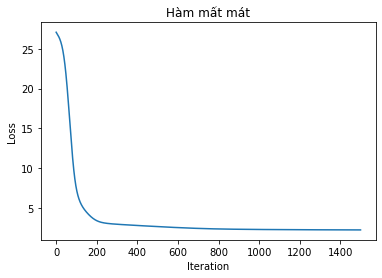

In [26]:
lr, n_iter = 0.01, 1500
history = []
for it in range(n_iter):
    E = mask * (X5.dot(W5) - Yn)                # sai số
    X5 -= lr * (E.dot(W5.T) + lamda * X5)       # đạo hàm theo X
    W5 -= lr * (X5.T.dot(E) + lamda * W5)       # đạo hàm theo W
    history.append(loss(X5, W5))
    if (it + 1) % 300 == 0:
        print(f"Iter {it+1:4d} | loss = {history[-1]:.3f}")

plt.plot(history); plt.xlabel("Iteration"); plt.ylabel("Loss"); plt.title("Hàm mất mát"); plt.show()

## 5.5. Dự đoán
$\hat{y}_{iu} = x_i w_u + \bar{y}_u$ (cộng lại điểm trung bình đã trừ ở bước chuẩn hoá)

In [27]:
Y_pred_mf = np.clip(X5.dot(W5) + mu, 0, 10).T   # (sinh viên x môn)
pd.DataFrame({"Điểm dự đoán": Y_pred_mf[0], "Điểm thật": full[0]}, index=subj_names).round(2)

,Điểm dự đoán,Điểm thật
Python,7.54,7.7
Java,7.39,7.4
CauTrucDuLieu,7.70,6.7
GiaiTich,6.51,6.5
DaiSo,7.42,7.4
XacSuat,6.75,7.3
BigData,6.97,8.6
KhaiThacDL,8.18,8.9
MayHoc,8.97,9.1
KhaiThacDoThi,9.07,9.1


## 5.6. Đánh giá bằng RMSE & so sánh 3 phương pháp

                        RMSE
Content-based (Ridge)  1.179
User-User CF (k=5)     1.115
Matrix Factorization   0.883


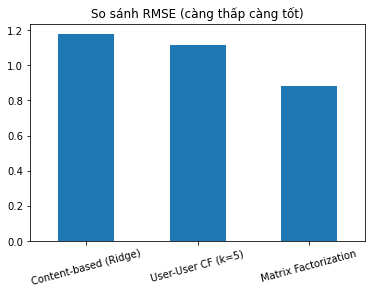

In [28]:
rmse_mf = rmse(test, lambda u, i: Y_pred_mf[u, i])
rmse_cf = rmse(test, lambda u, i: predict_user_cf(u, i, 5))

result = pd.DataFrame({"RMSE": [rmse_cb, rmse_cf, rmse_mf]},
                      index=["Content-based (Ridge)", "User-User CF (k=5)", "Matrix Factorization"])
print(result.round(3))
result.plot.bar(legend=False, rot=15, title="So sánh RMSE (càng thấp càng tốt)"); plt.show()